# Bayesian inference and MCMC for epidemic models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gem-epidemics/colab/blob/master/eitv/bayes_mcmc_workshop.ipynb)

This 90-minute workshop follows on from *Stochastic epidemic models in Python with
`gemlib`*. It introduces Bayesian inference, explains the basic idea behind Markov chain
Monte Carlo (MCMC), and then uses `gemlib` to estimate the parameters of an SIR model.

| Part | Topic | Time |
|---|---|---|
| 1 | Bayes' Theorem, priors and posteriors | ~20 min |
| 2 | A flavour of MCMC | ~15 min |
| 3 | Bayesian inference for an SIR model in `gemlib` | ~50 min |
| | Wrap-up | ~5 min |

## LEARNING OUTCOMES
- Identify the prior, likelihood and posterior in Bayes' Theorem, and apply it to a simple problem
- Explain why we need MCMC, and how the random-walk Metropolis-Hastings algorithm works
- Assess an MCMC run using trace plots and the acceptance rate
- Write an epidemic model as a Bayesian model in `gemlib`, and estimate its parameters with MCMC

Run the cells from top to bottom. Exercises have hidden solutions below them; try the
exercise first, then expand the solution if you get stuck.

## References
- Gelman, A. _et al._ (2013). _Bayesian Data Analysis_, 3rd ed. Chapman and Hall/CRC.
- Gilks, W., Richardson, S. and Spiegelhalter, D. (1995). _Markov Chain Monte Carlo in Practice_. Chapman and Hall.

## Setup

If you are using Google Colab, uncomment and run the `pip install` line first.

In [1]:
# !pip install gemlib

import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

## Part 1: Bayes' Theorem, priors and posteriors

Suppose we have a probability model for some data $X$ that depends on a parameter $\theta$,
so we know $Pr(X \mid \theta)$. Bayes' Theorem lets us turn this around and ask what we
have learned about $\theta$ having observed $X$:

$$
{\color{red}{Pr(\theta \mid X)}} = \frac{Pr(X \mid \theta)\, {\color{blue}{Pr(\theta)}}}{\color{green}{Pr(X)}}.
$$

* __Likelihood__ $Pr(X \mid \theta)$: the probability of the data given the parameter.
* <span style="color: blue">__Prior__</span> $Pr(\theta)$: what we believe about $\theta$ *before* seeing the data.
* <span style="color: green">__Model evidence__</span> $Pr(X) = \int Pr(X \mid \theta) Pr(\theta)\, d\theta$:
  a normalising constant that makes the posterior integrate to 1.
* <span style="color: red">__Posterior__</span> $Pr(\theta \mid X)$: what we believe about $\theta$ *after* seeing the data.

Because $Pr(X)$ does not depend on $\theta$, we often write

$$
Pr(\theta \mid X) \propto Pr(X \mid \theta)\, Pr(\theta),
$$

i.e. **posterior $\propto$ likelihood $\times$ prior**. The model evidence is usually an
intractable integral, and it is the reason we need algorithms such as MCMC.

### Example: diagnostic testing

A test's sensitivity $Se = Pr(T^+ \mid D^+)$ and specificity $Sp = Pr(T^- \mid D^-)$ are
probabilities of a test result *given* disease status. A clinician wants the reverse: the
probability of disease *given* the test result. Here, the prior is the prevalence of
disease, $p = Pr(D^+)$, and Bayes' Theorem gives the positive predictive value

$$
Pr(D^+ \mid T^+) = \frac{Se \times p}{Se \times p + (1 - Sp)(1 - p)}.
$$

````{exercise-start}
:label: bayes_ex1
````

A diagnostic test has 80% sensitivity and 99% specificity, and the disease prevalence is 0.5%.

1. Compute the probability that a randomly selected patient who tests positive has the disease.
2. Compute the probability that a patient who tests negative does *not* have the disease.
3. How does your answer to 1 change if the prevalence is 10%?

In [2]:
# your code here

````{exercise-end}
````

````{solution-start} bayes_ex1
:class: dropdown
````

In [3]:
def ppv(se, sp, prev):
    return se * prev / (se * prev + (1 - sp) * (1 - prev))


def npv(se, sp, prev):
    return sp * (1 - prev) / (sp * (1 - prev) + (1 - se) * prev)


print(f"PPV at 0.5% prevalence: {ppv(0.8, 0.99, 0.005):.3f}")
print(f"NPV at 0.5% prevalence: {npv(0.8, 0.99, 0.005):.3f}")
print(f"PPV at 10% prevalence:  {ppv(0.8, 0.99, 0.10):.3f}")

# The predictive values depend on the test characteristics *and* the prevalence (the prior).

PPV at 0.5% prevalence: 0.287
NPV at 0.5% prevalence: 0.999
PPV at 10% prevalence:  0.899


````{solution-end}
````

### Priors, likelihoods and posteriors for a continuous parameter

Suppose we want to estimate the probability $p$ that a coin comes up heads, and we observe
$x = 3$ heads in $n = 5$ tosses. The likelihood is Binomial:

$$
L(x \mid p) \propto p^{x}(1-p)^{n-x}.
$$

A prior for $p$ must live on $[0, 1]$, so a Beta distribution is a natural choice. It should
also be *honest*: do we really believe $p$ could be exactly 0 or 1?

$$
p \sim \operatorname{Beta}(a, b), \qquad f(p) \propto p^{a-1}(1-p)^{b-1}.
$$

Multiplying the likelihood by the prior and collecting terms,

$$
\pi(p \mid x) \propto p^{a + x - 1}(1-p)^{b + n - x - 1},
$$

which we recognise as another Beta distribution:

$$
p \mid x \sim \operatorname{Beta}(a + x,\; b + n - x).
$$

When the posterior is in the same family as the prior, the prior is called **conjugate**.
(The [Wikipedia page on conjugate priors](https://wikipedia.org/wiki/Conjugate_prior) has a
useful table.) Let's plot the prior, likelihood and posterior together.

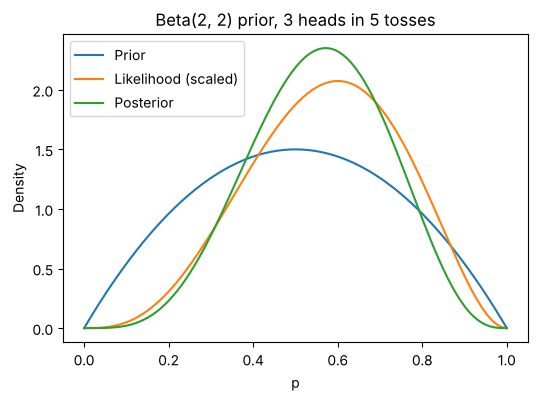

In [4]:
def plot_coin(a, b, x, n, ax=None):
    "Plot the Beta(a, b) prior, Binomial likelihood and Beta posterior for x heads in n tosses."
    p = np.linspace(0, 1, 200)
    prior = sp.stats.beta.pdf(p, a, b)
    likelihood = sp.stats.binom.pmf(x, n, p)
    likelihood = likelihood / np.trapezoid(likelihood, p)   # scale to area 1 for comparison
    posterior = sp.stats.beta.pdf(p, a + x, b + n - x)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(p, prior, label="Prior")
    ax.plot(p, likelihood, label="Likelihood (scaled)")
    ax.plot(p, posterior, label="Posterior")
    ax.set_xlabel("p")
    ax.set_ylabel("Density")
    ax.set_title(f"Beta({a}, {b}) prior, {x} heads in {n} tosses")
    ax.legend()
    return ax


plot_coin(a=2, b=2, x=3, n=5)
plt.show()

The posterior is a compromise between the prior (centred on 0.5) and the likelihood (peaked at
the maximum likelihood estimate $\hat p = 3/5 = 0.6$), and it is narrower than either.

````{exercise-start}
:label: bayes_ex2
````

Use `plot_coin` to explore how the prior and the data affect the posterior.

1. Try priors with $(a, b) = (1, 1)$, $(0.5, 0.5)$, $(20, 20)$ and $(10, 2)$. What beliefs does each
   represent? What is the $(1, 1)$ prior equivalent to?
2. Reset $a = b = 2$, and keep the proportion of heads at 60% but increase the number of tosses:
   $(x, n) = (3, 5)$, $(30, 50)$, $(300, 500)$. What happens to the influence of the prior?

In [5]:
# your code here

````{exercise-end}
````

````{solution-start} bayes_ex2
:class: dropdown
````

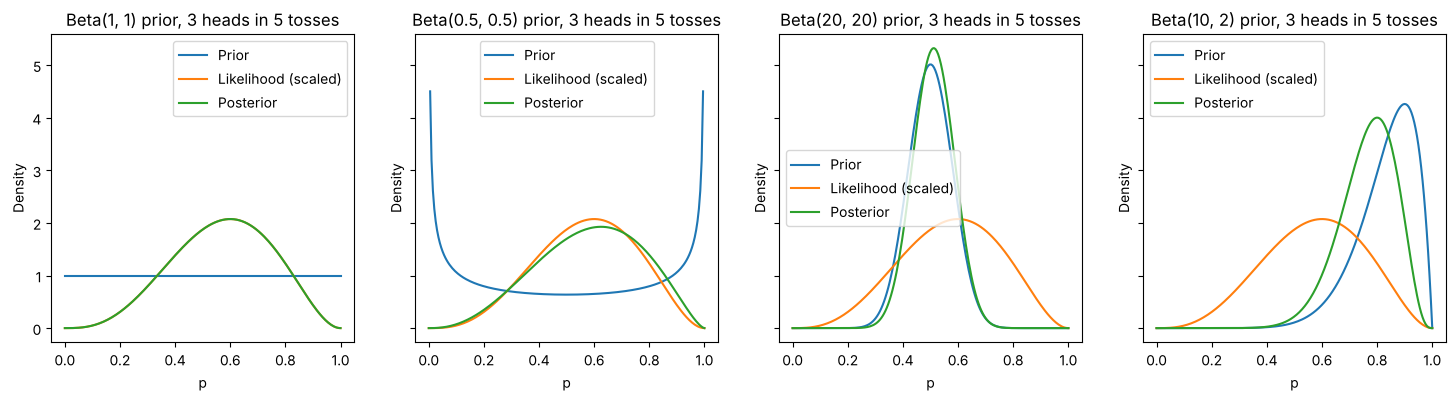

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (a, b) in zip(axes, [(1, 1), (0.5, 0.5), (20, 20), (10, 2)]):
    plot_coin(a, b, x=3, n=5, ax=ax)
plt.show()

# (1, 1) is a uniform prior: every value of p is equally plausible a priori, so the
# posterior has the same shape as the likelihood. Large a and b give a strong prior.

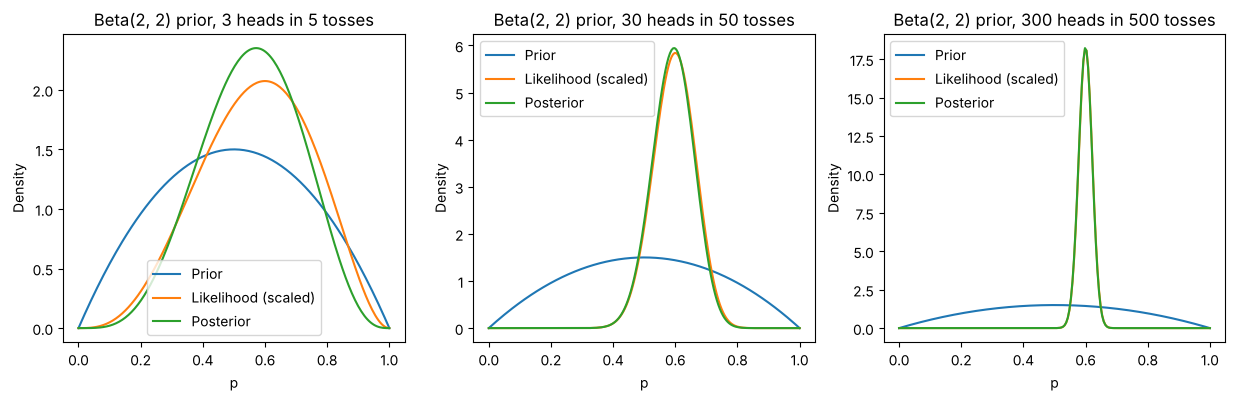

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (x, n) in zip(axes, [(3, 5), (30, 50), (300, 500)]):
    plot_coin(2, 2, x=x, n=n, ax=ax)
plt.show()

# As the amount of data grows, the likelihood dominates and the prior matters less.

````{solution-end}
````

## Part 2: A flavour of MCMC

For the coin, conjugacy gave us the posterior exactly. For an epidemic model there is no such
luck: we can evaluate likelihood $\times$ prior for any parameter value, but we cannot compute
the normalising constant, so we cannot write down the posterior.

**Markov chain Monte Carlo (MCMC)** gets around this. It produces a sequence (a *chain*) of
parameter values which, if run long enough, are draws from the posterior. It only ever needs
the *ratio* of posterior densities at two points, so the unknown normalising constant cancels.

### The random-walk Metropolis-Hastings algorithm

1. Start from an initial value $\theta^{(0)}$.
2. **Propose** a new value by taking a random step from the current one:
   $\theta' = \theta^{(i)} + \varepsilon$, with $\varepsilon \sim \operatorname{Normal}(0, s^2)$.
3. **Accept** the proposal with probability
   $\alpha = \min\left(1, \dfrac{\pi(\theta' \mid y)}{\pi(\theta^{(i)} \mid y)}\right)$;
   otherwise **stay** where we are, so $\theta^{(i+1)} = \theta^{(i)}$.
4. Repeat steps 2-3 many times.

The animation below runs this algorithm on the coin posterior from Part 1, starting from a poor
initial value of $p = 0.08$.

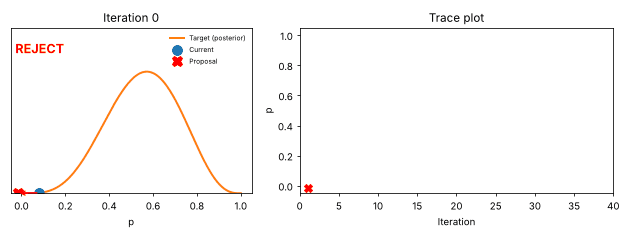

Things to notice:

- Moves **uphill** (to higher posterior density) are always accepted. Moves **downhill** are
  accepted only sometimes, so the chain explores the whole posterior rather than just climbing
  to its peak.
- When a proposal is **rejected**, the chain repeats its current value, giving flat sections in
  the trace plot.
- The first few iterations are spent walking from the poor starting value towards the bulk of
  the posterior. These **burn-in** samples are discarded.
- As the chain runs, the histogram of samples builds up the shape of the posterior.

To play with this yourself, try the interactive [MCMC demo](https://chi-feng.github.io/mcmc-demo/app.html)
(choose "RandomWalkMH").

### MCMC with `gemlib`

`gemlib` has the random-walk Metropolis-Hastings algorithm built in. We'll use it for the coin
example here, and for the epidemic model in Part 3. First, some imports.

In [8]:
import jax
import jax.numpy as jnp
import tensorflow_probability.substrates.jax as tfp

from gemlib.distributions import DiscreteTimeStateTransitionModel
from gemlib.mcmc import mcmc, rwmh

tfd = tfp.distributions
DTYPE = np.float32

We write the Bayesian model almost exactly as we write the maths,

\begin{align*}
p & \sim \operatorname{Beta}(2, 2) \\
x & \sim \operatorname{Binomial}(5, p),
\end{align*}

using TensorFlow Probability's `JointDistributionCoroutineAutoBatched`. Read each `yield` as
"$\sim$": it declares a random variable with a given distribution, and later variables can depend
on earlier ones. Each variable gets a `name` that we use to refer to it.

In [9]:
@tfd.JointDistributionCoroutineAutoBatched
def coin_model():
    p = yield tfd.Beta(DTYPE(2.0), DTYPE(2.0), name="p")
    yield tfd.Binomial(total_count=DTYPE(5.0), probs=p, name="heads")

**Conditioning** on the data means fixing ("pinning") the value of the data variable at what we
observed. The `log_prob` method of the pinned model then gives log(likelihood $\times$ prior), the
unnormalised log posterior, which is all MCMC needs.

In [10]:
coin_posterior = coin_model.experimental_pin(heads=DTYPE(3.0))

coin_posterior.log_prob(p=0.6)

Array(-0.69782996, dtype=float32)

Running MCMC needs two pieces:

- `rwmh(scale=...)` creates the Metropolis-Hastings **kernel** (one propose/accept step), with
  proposal standard deviation `scale`;
- `mcmc(...)` is the **driver**, which runs the kernel `num_samples` times from an initial position.

In [11]:
coin_samples, coin_info = mcmc(
    num_samples=5000,
    sampling_algorithm=rwmh(scale=0.2),
    target_log_density_fn=coin_posterior.log_prob,
    initial_position=coin_posterior.sample_unpinned(seed=jax.random.key(0)),
    seed=jax.random.key(1),
)

print(f"Acceptance rate: {np.mean(coin_info.is_accepted):.2f}")

Acceptance rate: 0.65


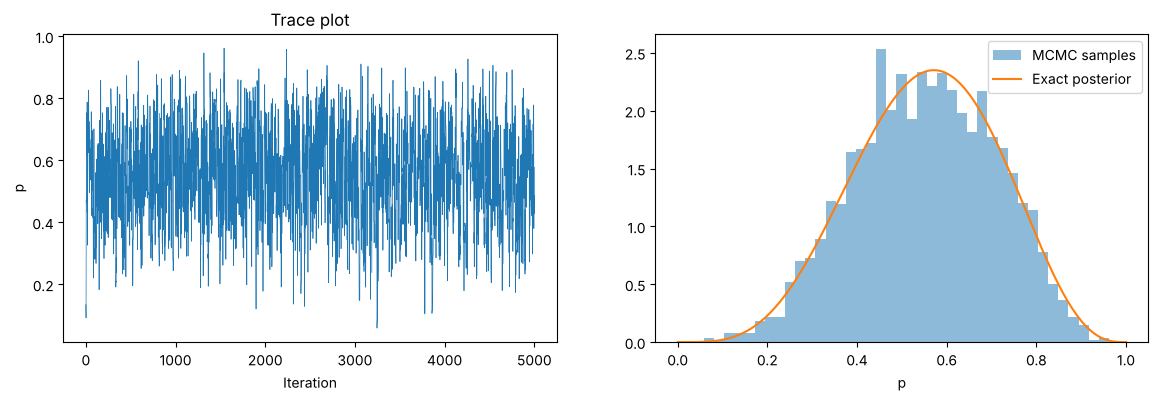

In [12]:
def plot_coin_mcmc(samples):
    "Trace plot and histogram of coin MCMC samples, compared with the exact posterior."
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(samples.p, linewidth=0.5)
    ax[0].set_xlabel("Iteration")
    ax[0].set_ylabel("p")
    ax[0].set_title("Trace plot")

    grid = np.linspace(0, 1, 200)
    ax[1].hist(samples.p, bins=40, density=True, alpha=0.5, label="MCMC samples")
    ax[1].plot(grid, sp.stats.beta.pdf(grid, 2 + 3, 2 + 5 - 3), label="Exact posterior")
    ax[1].set_xlabel("p")
    ax[1].legend()
    plt.show()


plot_coin_mcmc(coin_samples)

The MCMC samples match the exact Beta posterior from Part 1. Two practical points:

- A well-mixing chain's trace plot looks like a "hairy caterpillar", with no trends or long flat stretches.
- Successive samples are correlated, so 5000 MCMC samples carry less information than 5000
  independent draws.

````{exercise-start}
:label: bayes_ex3
````

The proposal `scale` controls the size of each random step. Re-run the coin MCMC with
`rwmh(scale=0.005)` and `rwmh(scale=5.0)`, print the acceptance rates and look at the plots.
What goes wrong in each case?

In [13]:
# your code here

````{exercise-end}
````

````{solution-start} bayes_ex3
:class: dropdown
````

scale = 0.005: acceptance rate 0.98


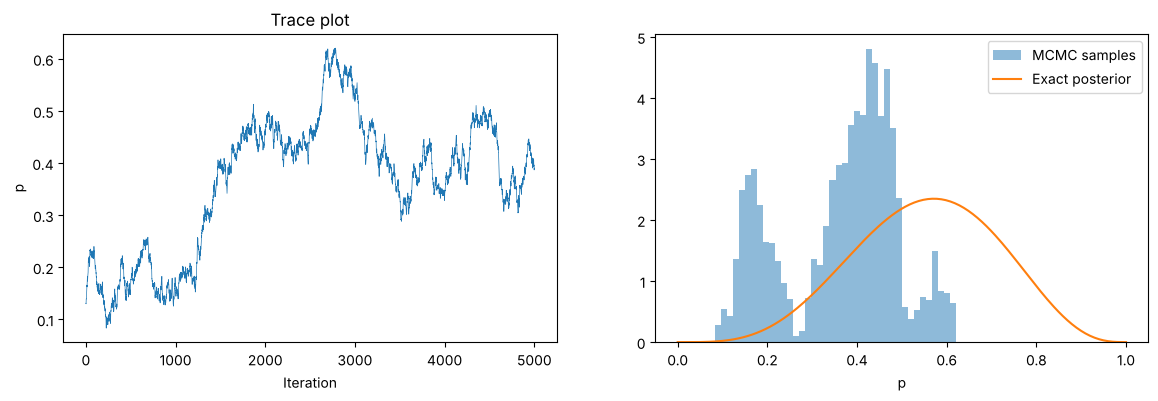

scale = 5.0: acceptance rate 0.04


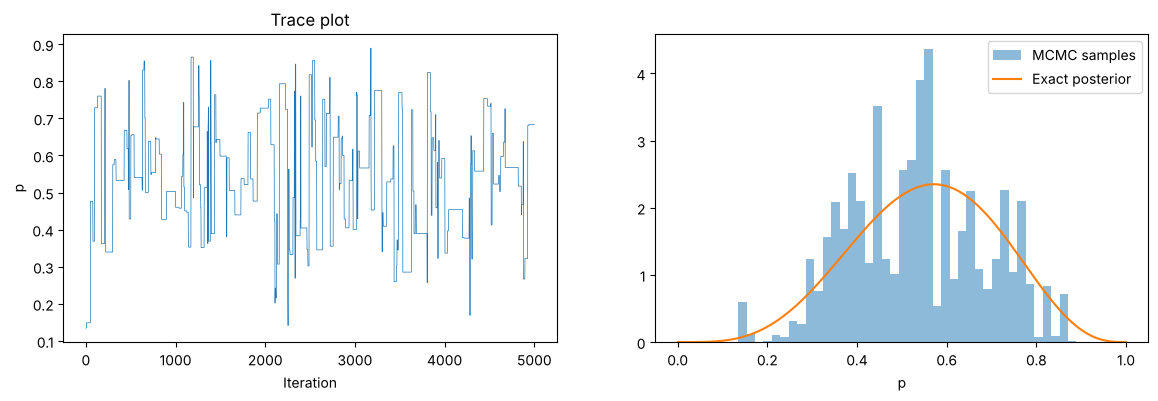

In [14]:
for scale in [0.005, 5.0]:
    s, inf = mcmc(
        num_samples=5000,
        sampling_algorithm=rwmh(scale=scale),
        target_log_density_fn=coin_posterior.log_prob,
        initial_position=coin_posterior.sample_unpinned(seed=jax.random.key(0)),
        seed=jax.random.key(1),
    )
    print(f"scale = {scale}: acceptance rate {np.mean(inf.is_accepted):.2f}")
    plot_coin_mcmc(s)

# Too small: almost every step is accepted, but the steps are tiny, so the chain crawls
# and does not explore the whole posterior in 5000 iterations.
# Too large: most proposals land outside [0, 1] or in low-density regions and are rejected,
# so the chain sticks at the same value for long stretches.

````{solution-end}
````

## Part 3: Bayesian inference for an SIR model in `gemlib`

We now put the pieces together. We will simulate an SIR epidemic with known parameters,
then pretend we don't know them and estimate them with MCMC. For now we assume that every
infection and recovery event is observed; the same machinery extends to more realistic
partially observed data.

### The epidemic model

This is the SIR model from the `gemlib` workshop, in a population of 1000 with one initial
infective. The transition rates are $\lambda^{SI} = \beta I / N$ and $\lambda^{IR} = \gamma$.

We wrap the model in a function `sir_model(beta, gamma)` that builds the model for given
parameter values. MCMC will need to rebuild the model every time it proposes new values of
$\beta$ and $\gamma$.

In [15]:
incidence_matrix = np.array([
    # SI  IR
    [-1,  0],   # S
    [ 1, -1],   # I
    [ 0,  1],   # R
], dtype=DTYPE)

initial_state = np.array([[999, 1, 0]], dtype=DTYPE)


def sir_model(beta, gamma):
    "Build a discrete-time SIR model for given parameter values."

    def si_rate(t, state):
        return beta * state[:, 1] / state.sum(axis=-1)

    def ir_rate(t, state):
        return gamma

    return DiscreteTimeStateTransitionModel(
        transition_rate_fn=[si_rate, ir_rate],
        incidence_matrix=incidence_matrix,
        initial_state=initial_state,
        num_steps=100,
        name="sir",
    )

### Simulating some data

We simulate one epidemic with $\beta = 0.3$ and $\gamma = 0.1$ and treat it as our observed
data. Recall that `sample` returns the **events**: the number of each transition on each day,
with shape `[T, N, R]` (time steps, units, transitions).

(100, 1, 2)


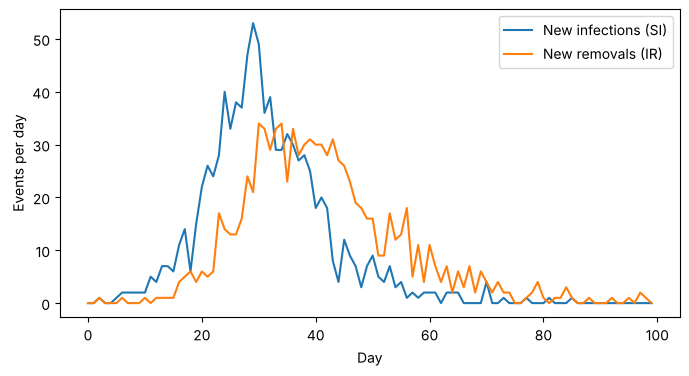

In [16]:
true_beta, true_gamma = 0.3, 0.1

observed = sir_model(true_beta, true_gamma).sample(seed=jax.random.key(1))
print(observed.shape)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(observed[:, 0, 0], label="New infections (SI)")
ax.plot(observed[:, 0, 1], label="New removals (IR)")
ax.set_xlabel("Day")
ax.set_ylabel("Events per day")
ax.legend()
plt.show()

### Writing down the Bayesian model

To complete the Bayesian model we add prior distributions for the parameters:

\begin{align*}
\beta & \sim \operatorname{Gamma}(1, 5) \\
\gamma & \sim \operatorname{Gamma}(1, 0.5) \\
Z & \sim \operatorname{SIR}(\beta, \gamma, \mathbf{x}_0)
\end{align*}

where $Z$ is the events array and $\mathbf{x}_0$ the initial state. (Gamma priors are positive,
as rates must be. Here they are deliberately vague.) This model can be drawn as a directed
acyclic graph (DAG): the parameters feed into the epidemic model, which generates the data.

```{mermaid}
:name: bayes-mcmc-dag
:alt: Bayesian DAG for the SIR model
:caption: Bayesian DAG for the SIR model

---
config:
  look: handDrawn
  theme: neutral
---

flowchart TD

  B((  β  )) --> STM((SIR))
  G((  γ  )) --> STM
```

As for the coin, we write this as a `JointDistributionCoroutineAutoBatched`. The final `yield`
is the `gemlib` epidemic model itself, which plays the role that the Binomial distribution played
for the coin.

In [17]:
@tfd.JointDistributionCoroutineAutoBatched
def model():
    beta = yield tfd.Gamma(concentration=DTYPE(1.0), rate=DTYPE(5.0), name="beta")
    gamma = yield tfd.Gamma(concentration=DTYPE(1.0), rate=DTYPE(0.5), name="gamma")
    yield sir_model(beta, gamma)   # named "sir" inside sir_model

### Simulating from the prior

The joint distribution can be sampled from top to bottom: draw $\beta$ and $\gamma$ from their
priors, then simulate an epidemic with those values. This *prior predictive* simulation is a
good check of whether our priors produce plausible epidemics.

(20,) (20, 100, 1, 2)


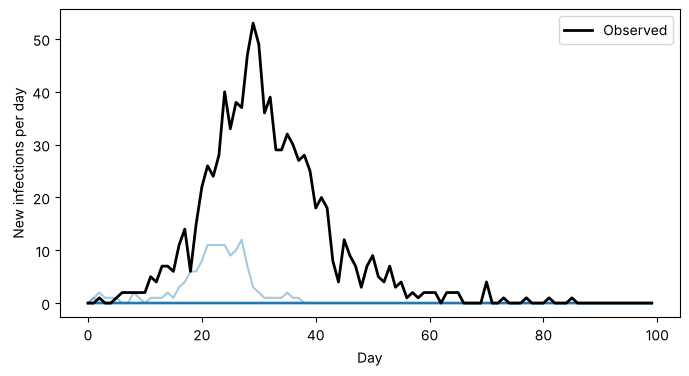

In [18]:
prior_sims = model.sample(sample_shape=20, seed=jax.random.key(3))
print(prior_sims.beta.shape, prior_sims.sir.shape)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(prior_sims.sir[:, :, 0, 0].T, color="C0", alpha=0.4)
ax.plot(observed[:, 0, 0], color="black", linewidth=2, label="Observed")
ax.set_xlabel("Day")
ax.set_ylabel("New infections per day")
ax.legend()
plt.show()

Most of the prior epidemics die out almost immediately. The vague $\operatorname{Gamma}(1, 0.5)$
prior for $\gamma$ has mean 2, i.e. an average infectious period of half a day, so most prior
draws have $R_0 = \beta/\gamma < 1$. Priors that look harmless on their own can imply
implausible epidemics, which is why prior predictive checks are worth doing.

To learn about $\beta$ and $\gamma$ we need to **condition** on the observed data. In code, conditioning means fixing ("pinning") the value of
the data variable. The result is a function of $\beta$ and $\gamma$ only, whose `log_prob`
method gives the log of likelihood $\times$ prior: the unnormalised log posterior.

In [19]:
conditioned_model = model.experimental_pin(sir=observed)

print(conditioned_model.log_prob(beta=0.3, gamma=0.1))
print(conditioned_model.log_prob(beta=0.2, gamma=0.1))

-363.26334
-425.7625


For intuition, here is the log posterior along a line of $\beta$ values, with $\gamma$ fixed at
its true value. MCMC explores this surface in both $\beta$ and $\gamma$ at once.

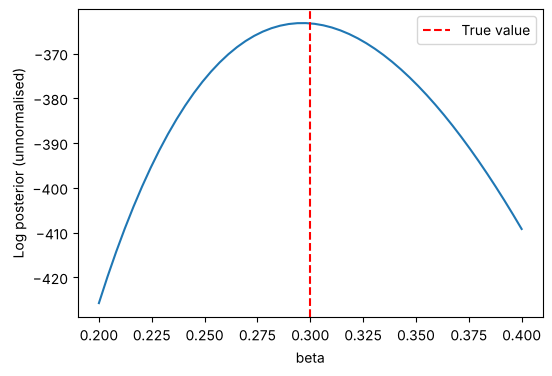

In [20]:
betas = np.linspace(0.2, 0.4, 50)
log_post = [conditioned_model.log_prob(beta=b, gamma=0.1) for b in betas]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(betas, log_post)
ax.axvline(true_beta, color="red", linestyle="--", label="True value")
ax.set_xlabel("beta")
ax.set_ylabel("Log posterior (unnormalised)")
ax.legend()
plt.show()

### Estimating the parameters with MCMC

This is exactly the same recipe as for the coin: an `rwmh` kernel, run by the `mcmc` driver,
targeting the `log_prob` of the conditioned model. The only difference is that the chain now
moves through two parameters, $\beta$ and $\gamma$, at once. We start the chain from a draw from
the prior.

In [21]:
initial_position = conditioned_model.sample_unpinned(seed=jax.random.key(42))
print(initial_position)

samples, info = mcmc(
    num_samples=10000,
    sampling_algorithm=rwmh(scale=0.01),
    target_log_density_fn=conditioned_model.log_prob,
    initial_position=initial_position,
    seed=jax.random.key(1),
)

print(f"Acceptance rate: {np.mean(info.is_accepted):.2f}")

StructTuple(
  beta=Array(0.16078365, dtype=float32),
  gamma=Array(1.9289501, dtype=float32)
)


Acceptance rate: 0.32


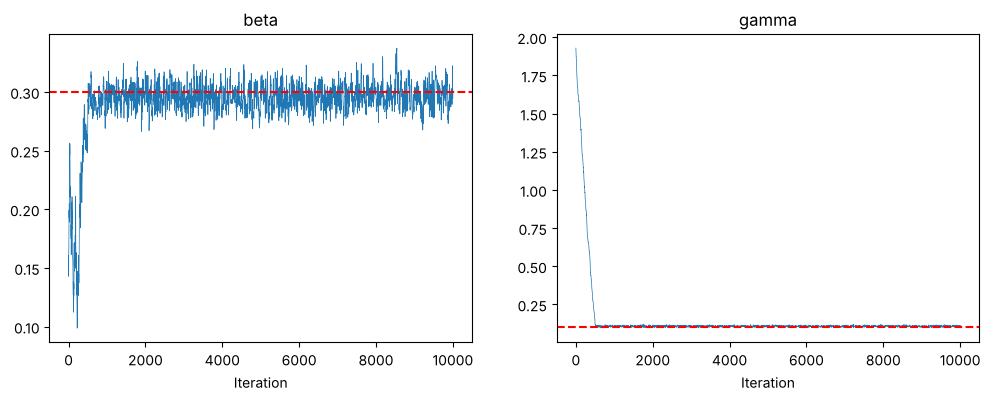

In [22]:
def trace_plot(samples, truth=None):
    "Trace plots for each parameter in a StructTuple of MCMC samples."
    names = samples._fields
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 4))
    for ax, name in zip(axes, names):
        ax.plot(getattr(samples, name), linewidth=0.5)
        if truth is not None:
            ax.axhline(truth[name], color="red", linestyle="--")
        ax.set_title(name)
        ax.set_xlabel("Iteration")
    plt.show()


truth = {"beta": true_beta, "gamma": true_gamma}
trace_plot(samples, truth)

The chain starts from wherever the prior draw put it, and quickly moves to the region of high
posterior probability around the true values (red lines). We discard the early iterations as
burn-in, then summarise the posterior with the remaining samples.

beta: mean 0.296, 95% credible interval (0.278, 0.316)


gamma: mean 0.108, 95% credible interval (0.101, 0.114)


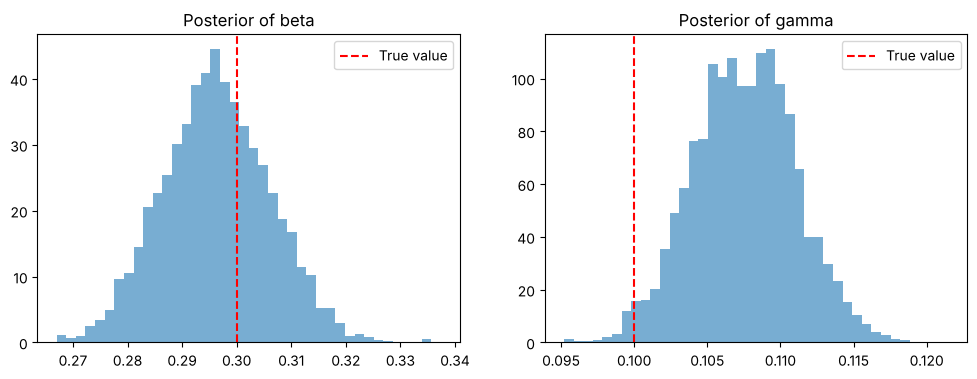

In [23]:
burn_in = 2000
posterior = {name: np.asarray(getattr(samples, name))[burn_in:] for name in samples._fields}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, draws) in zip(axes, posterior.items()):
    ax.hist(draws, bins=40, density=True, alpha=0.6)
    ax.axvline(truth[name], color="red", linestyle="--", label="True value")
    ax.set_title(f"Posterior of {name}")
    ax.legend()

    lower, upper = np.quantile(draws, [0.025, 0.975])
    print(f"{name}: mean {draws.mean():.3f}, 95% credible interval ({lower:.3f}, {upper:.3f})")
plt.show()

The posterior is centred close to the true values. It need not cover them exactly: the posterior
describes what *this particular* epidemic tells us, and by chance this realisation had slightly
faster recoveries than average.

````{exercise-start}
:label: bayes_ex4
````

The basic reproduction number of this model is $R_0 = \beta / \gamma$. Because we have samples
from the *joint* posterior of $\beta$ and $\gamma$, we get samples of $R_0$ simply by computing
it for each sample.

1. Compute the posterior samples of $R_0$ (after burn-in) and plot a histogram.
2. Report its posterior mean and 95% credible interval. Does it contain the true value of 3?

In [24]:
# your code here

````{exercise-end}
````

````{solution-start} bayes_ex4
:class: dropdown
````

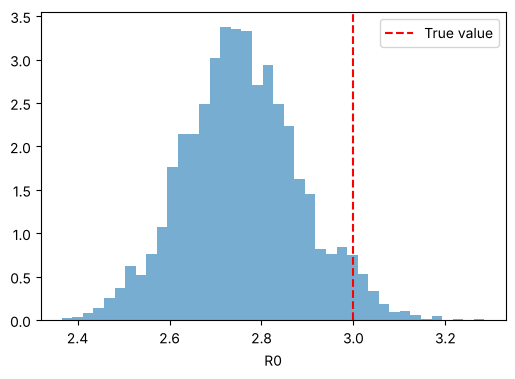

R0: mean 2.76, 95% credible interval (2.51, 3.02)


In [25]:
r0 = posterior["beta"] / posterior["gamma"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(r0, bins=40, density=True, alpha=0.6)
ax.axvline(true_beta / true_gamma, color="red", linestyle="--", label="True value")
ax.set_xlabel("R0")
ax.legend()
plt.show()

lower, upper = np.quantile(r0, [0.025, 0.975])
print(f"R0: mean {r0.mean():.2f}, 95% credible interval ({lower:.2f}, {upper:.2f})")

````{solution-end}
````

````{exercise-start}
:label: bayes_ex5
````

Investigate the behaviour of the sampler, as you did for the coin in Part 2.

1. Re-run `mcmc` with `rwmh(scale=0.001)` and `rwmh(scale=0.1)`. Compare the acceptance rates and
   trace plots with `scale=0.01`.
2. Run a second chain from a different starting point (use a different `seed` in
   `sample_unpinned`). Do both chains settle in the same place?

In [26]:
# your code here

````{exercise-end}
````

````{solution-start} bayes_ex5
:class: dropdown
````

scale = 0.001: acceptance rate 0.74


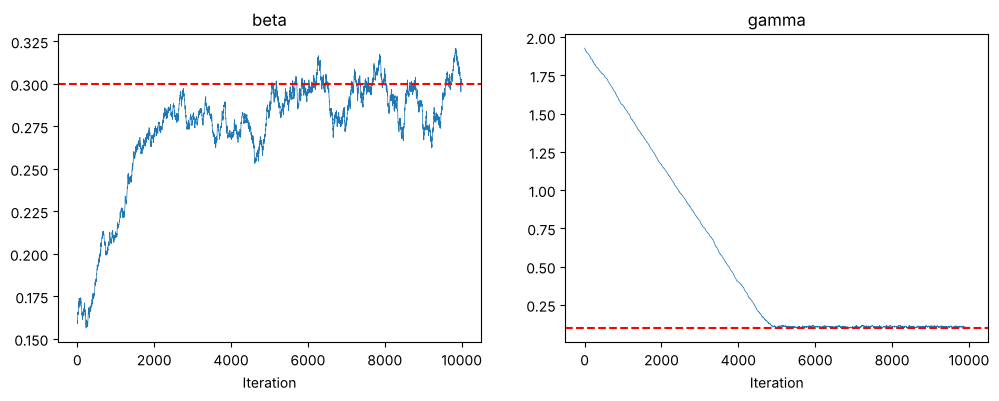

scale = 0.1: acceptance rate 0.01


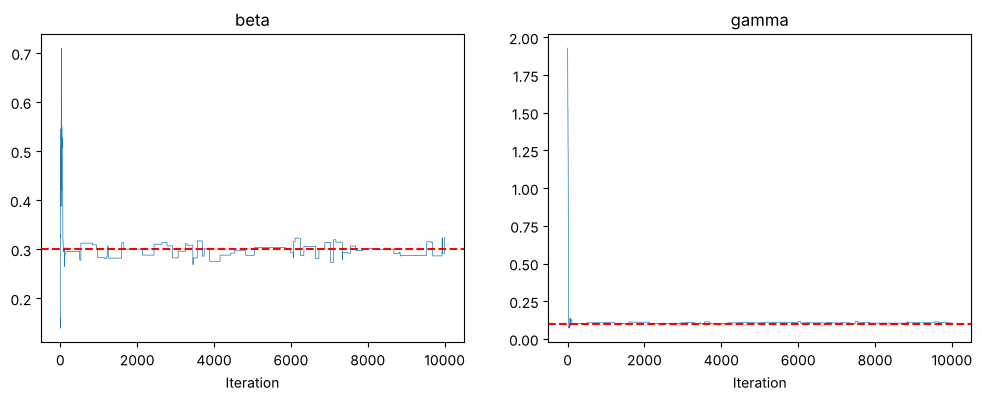

In [27]:
for scale in [0.001, 0.1]:
    s, inf = mcmc(
        num_samples=10000,
        sampling_algorithm=rwmh(scale=scale),
        target_log_density_fn=conditioned_model.log_prob,
        initial_position=initial_position,
        seed=jax.random.key(1),
    )
    print(f"scale = {scale}: acceptance rate {np.mean(inf.is_accepted):.2f}")
    trace_plot(s, truth)

# scale = 0.001: high acceptance, but the chain moves slowly and needs a long burn-in.
# scale = 0.1: very low acceptance; the chain gets stuck for long stretches.

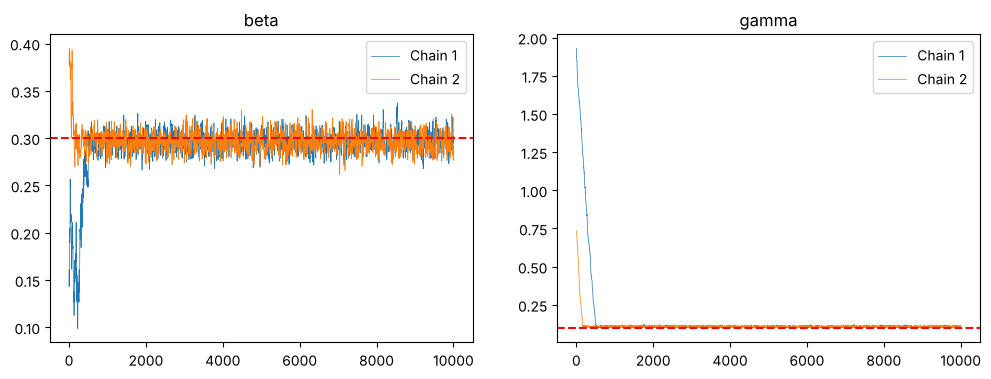

In [28]:
samples2, info2 = mcmc(
    num_samples=10000,
    sampling_algorithm=rwmh(scale=0.01),
    target_log_density_fn=conditioned_model.log_prob,
    initial_position=conditioned_model.sample_unpinned(seed=jax.random.key(7)),
    seed=jax.random.key(2),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["beta", "gamma"]):
    ax.plot(getattr(samples, name), linewidth=0.5, label="Chain 1")
    ax.plot(getattr(samples2, name), linewidth=0.5, label="Chain 2")
    ax.axhline(truth[name], color="red", linestyle="--")
    ax.set_title(name)
    ax.legend()
plt.show()

# Both chains converge to the same region: a basic check that the sampler has found the posterior.

````{solution-end}
````

## Wrap-up

Today we have:

- used Bayes' Theorem to combine a prior with a likelihood, and seen conjugacy give the posterior exactly;
- seen how the random-walk Metropolis-Hastings algorithm works, and how the proposal scale affects mixing;
- expressed an SIR model as a Bayesian model in `gemlib` and TensorFlow Probability;
- estimated $\beta$, $\gamma$ and $R_0$ from simulated data with `gemlib.mcmc`.

### Where next?

- In real outbreaks we rarely observe every infection and recovery. `gemlib` treats the missing
  events as extra unknowns and samples them alongside the parameters with MCMC.
- `gemlib.mcmc` also provides more efficient samplers, e.g. adaptive random-walk Metropolis and
  Hamiltonian Monte Carlo; see the [documentation](https://gem-epidemics.gitlab.io/gemlib).
- The full course notebooks cover the Gibbs sampler, joint distributions in more depth, and finding
  maximum a posteriori (MAP) estimates.